# Explore the Cell Phenotyping Matrix on SLIDE-045

`Cell Phenotyping Matrix.csv` (repo root) is meant to be the single definition of cell types: markers down the side, cell types across the top, and each entry `+`, `-`, or `+/-`. `analyze_cell_types_from_markers.ipynb` does not read it yet. It uses its own hardcoded `CELL_TYPE_RULES`, several of which call a cell type from one marker.

This notebook applies the matrix as written to our binary calls, shows which requirements remove the cells, and ends with suggested revisions to discuss before the matrix is wired into the pipeline. Nothing is written; every input is read only.

| | Path | Use |
|---|---|---|
| In | `Cell Phenotyping Matrix.csv` | cell-type definitions |
| In | `output/celldive_protein_matrix.h5ad` | `layers["binary"]`, built from `output/gating_thresholds.csv` |
| In | `output/gating_thresholds.csv` | the per-marker cutoffs behind the binary layer |
| In | `output/celldive_protein_matrix_celltypes.h5ad` | current labels from the hardcoded rules, for comparison |
| In | `qc/SLIDE-045/qc_summary.json` | automated per-marker QC |

How the matrix is read here:

- `+`: the marker must be positive.
- `-`: the marker must be negative.
- `+/-`: not checked.
- DAPI is `+` in every column, but every cell is already a Cellpose nucleus, so DAPI is not checked.
- "All Leukocytes (CD45+ mask)" and "Proliferating (Ki67 mask)" are overlays, not exclusive cell types. They are reported separately and left out of the one-type-per-cell counts.

All 926,006 cells are used, including cells the current pipeline labels `Artifact_Spillover`, so the matrix is judged on the same cells the thresholds were set on.

**Kernel:** `napari-env`.

## 1. Imports and paths

In [1]:
import json
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MATRIX_CSV = PROJECT_ROOT / "Cell Phenotyping Matrix.csv"
BINARY_H5AD = PROJECT_ROOT / "output" / "celldive_protein_matrix.h5ad"
GATING_CSV = PROJECT_ROOT / "output" / "gating_thresholds.csv"
CELLTYPES_H5AD = PROJECT_ROOT / "output" / "celldive_protein_matrix_celltypes.h5ad"
QC_JSON = PROJECT_ROOT / "qc" / "SLIDE-045" / "qc_summary.json"

# Matrix row labels that differ from adata.var_names.
MARKER_ALIASES = {"COLA1": "COL1A1", "DAPI (1&2)": "DAPI"}
MASK_COLUMNS = ["All Leukocytes (CD45+ mask)", "Proliferating (Ki67 mask)"]
NOT_CHECKED = {"DAPI"}

for p in [MATRIX_CSV, BINARY_H5AD, GATING_CSV, CELLTYPES_H5AD, QC_JSON]:
    print(f"{'ok     ' if p.exists() else 'MISSING'}  {p.relative_to(PROJECT_ROOT)}")

ok       Cell Phenotyping Matrix.csv
ok       output/celldive_protein_matrix.h5ad
ok       output/gating_thresholds.csv
ok       output/celldive_protein_matrix_celltypes.h5ad
ok       qc/SLIDE-045/qc_summary.json


## 2. Load the matrix and the binary calls

In [2]:
raw_matrix = pd.read_csv(MATRIX_CSV).set_index("Marker")
matrix = raw_matrix.rename(index=MARKER_ALIASES).apply(lambda s: s.str.strip())

unexpected = set(np.unique(matrix.values)) - {"+", "-", "+/-"}
if unexpected:
    raise ValueError(f"Unexpected matrix values: {sorted(unexpected)}")

lineage_types = [c for c in matrix.columns if c not in MASK_COLUMNS]
print(f"{len(matrix)} markers x {len(matrix.columns)} columns "
      f"({len(lineage_types)} cell types + {len(MASK_COLUMNS)} masks)")
print("Renamed rows:", {k: v for k, v in MARKER_ALIASES.items() if k in raw_matrix.index})
matrix

21 markers x 13 columns (11 cell types + 2 masks)
Renamed rows: {'DAPI (1&2)': 'DAPI'}


,Tumor / Epithelial,Endothelial,Fibroblast / Myofibroblast,Smooth Muscle,T cell CD8,T cell other,B / Plasma cell,NK cell,M1-like Macrophage,M2-like Macrophage,Dendritic Cell,All Leukocytes (CD45+ mask),Proliferating (Ki67 mask)
Marker,,,,,,,,,,,,,
DAPI,+,+,+,+,+,+,+,+,+,+,+,+,+
CD45,-,-,-,-,+,+,+,+,+,+,+,+,+/-
PANCK,+,-,-,-,-,-,-,-,-,-,-,-,+/-
EPCAM,+,-,-,-,-,-,-,-,-,-,-,-,+/-
VIM,+/-,+/-,+,+/-,-,-,-,-,+/-,+/-,+/-,+/-,+/-
ACTA2,-,-,+/-,+,-,-,-,-,-,-,-,-,+/-
COL1A1,-,-,+,-,-,-,-,-,-,-,-,-,+/-
CD31,-,+,-,-,-,-,-,-,-,-,-,-,+/-
CD3E,-,-,-,-,+,+,-,-,-,-,-,+/-,+/-


In [3]:
adata = ad.read_h5ad(BINARY_H5AD)
B = adata.layers["binary"]
B = np.asarray(B.toarray() if hasattr(B, "toarray") else B).astype(bool)
var_names = list(adata.var_names)
n_cells = adata.n_obs
pos = {m: B[:, var_names.index(m)] for m in var_names}

print(f"Cells: {n_cells:,}")
print("In the matrix but not in the data:", [m for m in matrix.index if m not in pos])
print("In the data but not in the matrix:", [m for m in var_names if m not in matrix.index])

Cells: 926,006
In the matrix but not in the data: []
In the data but not in the matrix: ['PDGFRA', 'DAPI2']


## 3. Positive rate and QC status per marker

Every `-` in the matrix trusts that marker's negative call. A marker called positive in a large share of cells removes that share from every column where it is `-`. `n_minus_columns` is how many of the 11 cell types require the marker to be negative.

The two QC sources do not agree. `qc_summary.json` flags CD20, CD38, and COL1A1 as failed antibodies. The manual review in `qc/report/SLIDE-045_failed_channels_cd20_pdgfra_epcam.md` treats EPCAM and PDGFRA as failed, CD20 as a working stain with heavy spillover, and COL1A1 as working.

In [4]:
qc = json.loads(QC_JSON.read_text())["modules"]["marker"]["metrics"]["per_marker"]
gating = pd.read_csv(GATING_CSV).set_index("marker")["threshold"]

checked = [m for m in matrix.index if m not in NOT_CHECKED]
marker_df = pd.DataFrame({
    "pct_positive": [100 * pos[m].mean() for m in checked],
    "threshold": [gating.get(m, np.nan) for m in checked],
    "qc_status": [qc.get(m, {}).get("status", "") for m in checked],
    "qc_antibody_failed": [qc.get(m, {}).get("antibody_failed", "") for m in checked],
    "n_plus_columns": [int((matrix.loc[m, lineage_types] == "+").sum()) for m in checked],
    "n_minus_columns": [int((matrix.loc[m, lineage_types] == "-").sum()) for m in checked],
}, index=checked).sort_values("pct_positive", ascending=False)
marker_df.round(1)

,pct_positive,threshold,qc_status,qc_antibody_failed,n_plus_columns,n_minus_columns
CD14,49.4,100.0,pass,False,2,9
HLADR,45.5,217.2,pass,False,3,5
ACTA2,35.6,472.2,pass,False,1,9
CD8a,34.1,600.0,pass,False,1,10
CD3E,28.7,655.6,pass,False,2,9
VIM,23.1,2351.2,pass,False,1,4
CD31,22.9,80.0,pass,False,1,10
CD45,21.8,494.8,pass,False,7,4
CD56,18.7,200.0,pass,False,1,10
COL1A1,18.5,3401.6,fail,True,1,10


## 4. Apply the matrix as written

In [5]:
def requirements(col):
    plus = [m for m, v in matrix[col].items() if v == "+" and m not in NOT_CHECKED]
    minus = [m for m, v in matrix[col].items() if v == "-" and m not in NOT_CHECKED]
    return plus, minus


def match(plus, minus):
    ok = np.ones(n_cells, dtype=bool)
    for m in plus:
        ok &= pos[m]
    for m in minus:
        ok &= ~pos[m]
    return ok


def summarize(matches, label):
    k = np.column_stack([matches[t] for t in lineage_types]).sum(axis=1)
    counts = pd.Series({t: int(matches[t].sum()) for t in lineage_types}, name=label)
    split = {
        "no match": round(100 * float(np.mean(k == 0)), 2),
        "one type": round(100 * float(np.mean(k == 1)), 2),
        "more than one": round(100 * float(np.mean(k > 1)), 2),
    }
    return counts, split


strict = {t: match(*requirements(t)) for t in matrix.columns}
strict_counts, strict_split = summarize(strict, "strict")

strict_table = pd.DataFrame({
    "required_plus": [" ".join(requirements(t)[0]) for t in lineage_types],
    "n_required_minus": [len(requirements(t)[1]) for t in lineage_types],
    "cells": strict_counts.values,
    "pct": (100 * strict_counts / n_cells).round(2).values,
}, index=lineage_types)

print("Cells by number of matching cell types (%):", strict_split)
for t in MASK_COLUMNS:
    print(f"{t}: {strict[t].sum():,} cells ({100 * strict[t].mean():.1f}%)")
strict_table

Cells by number of matching cell types (%): {'no match': 88.59, 'one type': 11.41, 'more than one': 0.0}
All Leukocytes (CD45+ mask): 105,243 cells (11.4%)
Proliferating (Ki67 mask): 92,649 cells (10.0%)


,required_plus,n_required_minus,cells,pct
Tumor / Epithelial,PANCK EPCAM,15,60,0.01
Endothelial,CD31,17,8758,0.95
Fibroblast / Myofibroblast,VIM COL1A1,15,2176,0.23
Smooth Muscle,ACTA2,17,93967,10.15
T cell CD8,CD45 CD3E CD8a CD45RO CD44,12,95,0.01
T cell other,CD45 CD3E CD45RO CD44,13,50,0.01
B / Plasma cell,CD45 CD20 CD38,13,60,0.01
NK cell,CD45 CD56,16,24,0.00
M1-like Macrophage,CD45 CD68 CD14 HLADR,12,16,0.00
M2-like Macrophage,CD45 CD68 CD14 CD163 HLADR,11,384,0.04


## 5. Which requirement removes the cells

For each cell type, start from the cells that meet every `+`. Then count how many of those are positive for each `-` marker. One marker removing most of the candidates means that exclusion alone decides the cell type.

The heatmap columns are ordered by positive rate, highest on the left. Blank means the marker is `+` or `+/-` for that cell type.

In [6]:
rows = []
for t in lineage_types:
    plus, minus = requirements(t)
    base = match(plus, [])
    for m in minus:
        rows.append({
            "cell_type": t,
            "excluding_marker": m,
            "plus_candidates": int(base.sum()),
            "removed": int((base & pos[m]).sum()),
        })
blockers = pd.DataFrame(rows)
blockers["pct_of_candidates"] = (
    100 * blockers["removed"] / blockers["plus_candidates"].clip(lower=1)
).round(1)

(blockers.sort_values(["cell_type", "removed"], ascending=[True, False])
    .groupby("cell_type").head(3)
    .set_index(["cell_type", "excluding_marker"]))

plus_candidates  removed  \
cell_type                  excluding_marker                             
B / Plasma cell            CD3E                        25018    22579   
                           CD14                        25018    22209   
                           CD8a                        25018    21115   
Dendritic Cell             CD14                        66618    63041   
                           CD8a                        66618    55565   
                           CD3E                        66618    53222   
Endothelial                HLADR                      212207   150360   
                           CD14                       212207   147999   
                           CD8a                       212207   102232   
Fibroblast / Myofibroblast CD14                        48513    40477   
                           HLADR                       48513    32319   
                           CD8a                        48513    31610   
M1-like Macrophage         CD8a                        44338    36368   
                           CD3E                        44338    35422   
                           CD163                       44338    29632   
M2-like Macrophage         CD8a                        29632    24380   
                           CD3E                        29632    23713   
                           CD45RO                      29632    16402   
NK cell                    HLADR                        8335     7380   
                           CD3E                         8335     7311   
                           CD14                         8335     7000   
Smooth Muscle              CD56                       329336   137375   
                           CD14                       329336    75058   
                           CD8a                       329336    69236   
T cell CD8                 CD14                        37862    35502   
                           CD20                        37862    27736   
                           CD11c                       37862    20229   
T cell other               CD8a                        40741    37862   
                           CD14                        40741    37846   
                           CD20                        40741    29642   
Tumor / Epithelial         HLADR                       16828    14549   
                           CD8a                        16828    10870   
                           CD14                        16828    10642   

                                             pct_of_candidates  
cell_type                  excluding_marker                     
B / Plasma cell            CD3E                           90.3  
                           CD14                           88.8  
                           CD8a                           84.4  
Dendritic Cell             CD14                           94.6  
                           CD8a                           83.4  
                           CD3E                           79.9  
Endothelial                HLADR                          70.9  
                           CD14                           69.7  
                           CD8a                           48.2  
Fibroblast / Myofibroblast CD14                           83.4  
                           HLADR                          66.6  
                           CD8a                           65.2  
M1-like Macrophage         CD8a                           82.0  
                           CD3E                           79.9  
                           CD163                          66.8  
M2-like Macrophage         CD8a                           82.3  
                           CD3E                           80.0  
                           CD45RO                         55.4  
NK cell                    HLADR                          88.5  
                           CD3E                           87.7  
                           CD14                           8

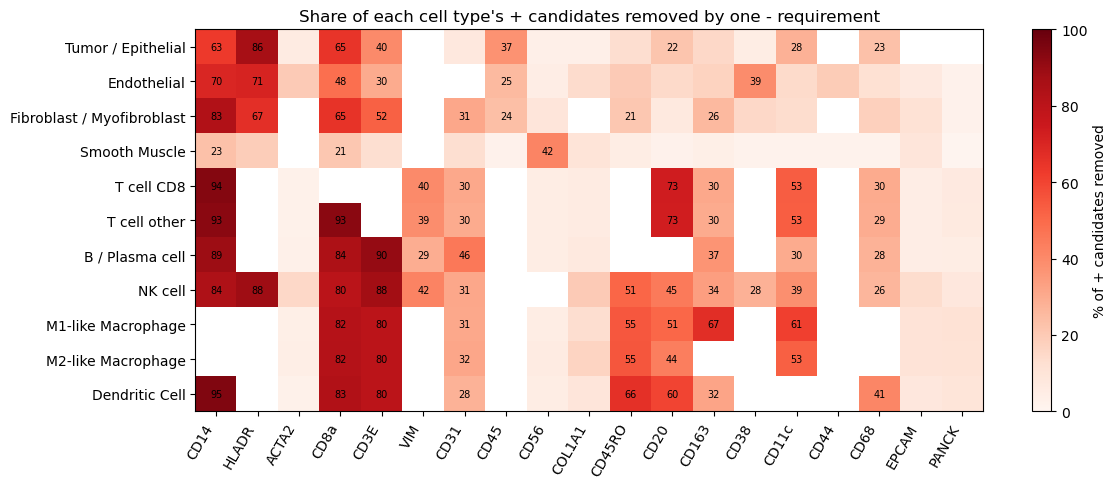

In [7]:
heat = blockers.pivot(index="cell_type", columns="excluding_marker", values="pct_of_candidates")
heat = heat.reindex(index=lineage_types, columns=[m for m in marker_df.index if m in heat.columns])

fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(heat.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=60, ha="right")
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if np.isfinite(v) and v >= 20:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="% of + candidates removed")
ax.set_title("Share of each cell type's + candidates removed by one - requirement")
fig.tight_layout()
plt.show()

## 6. Sensitivity test: lineage exclusions only

This is a test of how much the strictness matters, not a proposed matrix. Starting from the matrix as written:

- Drop `+` on activation and memory markers: CD45RO, CD44, CD38, HLADR, CD14.
- Keep `-` only for lineage markers: CD45, PANCK, CD31, CD3E, CD20, CD68.
- Also keep the two exclusions that separate subtypes: CD8a- for "T cell other" and CD163- for "M1-like Macrophage".

In [8]:
FUNCTIONAL_PLUS = {"CD45RO", "CD44", "CD38", "HLADR", "CD14"}
LINEAGE_MINUS = {"CD45", "PANCK", "CD31", "CD3E", "CD20", "CD68"}
SUBTYPE_MINUS = {"T cell other": {"CD8a"}, "M1-like Macrophage": {"CD163"}}


def lineage_requirements(t):
    plus, minus = requirements(t)
    keep = LINEAGE_MINUS | SUBTYPE_MINUS.get(t, set())
    return [m for m in plus if m not in FUNCTIONAL_PLUS], [m for m in minus if m in keep]


lineage_only = {t: match(*lineage_requirements(t)) for t in lineage_types}
lineage_counts, lineage_split = summarize(lineage_only, "lineage_only")

compare = pd.concat([strict_counts, lineage_counts], axis=1)
compare["lineage_only_plus"] = [" ".join(lineage_requirements(t)[0]) for t in lineage_types]
compare["lineage_only_minus"] = [" ".join(lineage_requirements(t)[1]) for t in lineage_types]
print("strict       (%):", strict_split)
print("lineage only (%):", lineage_split)
compare

strict       (%): {'no match': 88.59, 'one type': 11.41, 'more than one': 0.0}
lineage only (%): {'no match': 53.29, 'one type': 46.52, 'more than one': 0.19}


,strict,lineage_only,lineage_only_plus,lineage_only_minus
Tumor / Epithelial,60,5802,PANCK EPCAM,CD45 CD31 CD3E CD20 CD68
Endothelial,8758,115945,CD31,CD45 PANCK CD3E CD20 CD68
Fibroblast / Myofibroblast,2176,12022,VIM COL1A1,CD45 PANCK CD31 CD3E CD20 CD68
Smooth Muscle,93967,249317,ACTA2,CD45 PANCK CD31 CD3E CD20 CD68
T cell CD8,95,26864,CD45 CD3E CD8a,PANCK CD31 CD20 CD68
T cell other,50,12459,CD45 CD3E,PANCK CD31 CD8a CD20 CD68
B / Plasma cell,60,6741,CD45 CD20,PANCK CD31 CD3E CD68
NK cell,24,314,CD45 CD56,PANCK CD31 CD3E CD20 CD68
M1-like Macrophage,16,401,CD45 CD68,PANCK CD31 CD3E CD20 CD163
M2-like Macrophage,384,1923,CD45 CD68 CD163,PANCK CD31 CD3E CD20


## 7. Compare with the current hardcoded labels

Rows are the labels in `celldive_protein_matrix_celltypes.h5ad`, from `CELL_TYPE_RULES`. Columns are the lineage-only test. Cells matching more than one type are labeled "more than one". Values are the percent of each current label.

In [9]:
current = ad.read_h5ad(CELLTYPES_H5AD, backed="r")
if not (current.obs_names == adata.obs_names).all():
    raise ValueError("Cell order differs between the binary and cell-type h5ad files")
current_label = current.obs["cell_type"].astype(str).values

M = np.column_stack([lineage_only[t] for t in lineage_types])
k = M.sum(axis=1)
matrix_label = np.where(
    k == 0, "no match",
    np.where(k > 1, "more than one", np.array(lineage_types, dtype=object)[M.argmax(axis=1)]),
)

xt = pd.crosstab(
    pd.Series(current_label, name="current label"),
    pd.Series(matrix_label, name="lineage-only matrix"),
)
xt = xt.loc[xt.sum(axis=1).sort_values(ascending=False).index]
pct = (100 * xt.div(xt.sum(axis=1), axis=0)).round(1)
pct.insert(0, "n_cells", xt.sum(axis=1))
pct

lineage-only matrix,n_cells,B / Plasma cell,Dendritic Cell,Endothelial,Fibroblast / Myofibroblast,M1-like Macrophage,M2-like Macrophage,NK cell,Smooth Muscle,T cell CD8,T cell other,Tumor / Epithelial,more than one,no match
current label,,,,,,,,,,,,,,
Myofibroblast,261073,0.0,0.0,9.8,0.0,0.0,0.0,0.0,77.9,0.0,0.0,0.0,0.5,11.7
Artifact_Spillover,146584,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
Unassigned,106703,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,100.0
Collagen_stroma,95916,0.0,0.0,10.0,9.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,80.7
Mesenchymal,68725,0.0,0.0,39.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,61.0
Epithelial_EPCAM,61775,0.0,0.0,13.3,1.6,0.0,0.0,0.0,32.7,0.0,0.0,0.0,0.3,52.1
Endothelial,53082,0.0,0.0,77.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,22.3
Fibroblast,48012,0.0,0.0,9.1,1.1,0.0,0.0,0.0,49.9,0.0,0.0,0.0,0.2,39.7
CD8_T,34340,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,78.2,0.0,0.0,0.0,21.8


## 8. Suggested revisions to the matrix

Numbers below are from this notebook's run on the current `output/` files (October 2026). Re-running after a threshold change will move them.

### What the run shows

- **As written, the matrix assigns 11.4% of cells.** 88.6% match no cell type, and no cell matches two. Every immune type gets 16 to 384 cells, and Tumor / Epithelial gets 60.
- **The cause is the number of `-` requirements.** Each cell type requires 11 to 17 markers to be negative. One over-called marker is enough to remove most candidates. CD14 (49.4% of cells positive) removes 94% of the dendritic and CD8 T cell candidates. HLADR (45.5%) removes 89% of the NK candidates and 87% of the tumor candidates.
- **Keeping only lineage exclusions brings assignment to 46.5%,** with 0.19% of cells matching more than one type (section 6). That is a test, not a proposal, but it shows the `-` entries are the main problem.
- **Some of what remains is the cutoffs, not the matrix.** In the lineage-only test, Smooth Muscle (ACTA2+) gets 249,317 cells and Endothelial (CD31+) gets 115,945. ACTA2 is positive in 35.6% of cells and CD31 in 22.9%. Of the cells the current rules call `Mesenchymal` (VIM+), 53% are CD31+.

### Suggested changes

1. **Use `-` only for real exclusions.** Keep `-` where a positive call rules the cell type out, such as CD45 for non-immune types, PANCK, CD31, CD3E, CD20, and CD68 across lineages. Change "not expected" markers to `+/-`. This is the largest single change.
2. **Stop requiring activation and memory markers for lineage calls.** Both T cell columns require CD45RO+ and CD44+, which excludes naive T cells. Move CD45RO to a memory subtype instead. HLADR+ and CD14+ are required for macrophages and HLADR+ for dendritic cells. Tissue macrophages vary on CD14, and CD14 is positive in half the slide.
3. **Split "B / Plasma cell" into two columns.** The column requires CD20+ and CD38+ together. B cells are CD20+ with variable CD38, and plasma cells are CD38-high and usually lose CD20.
4. **Decide what to do with failed channels.** Tumor / Epithelial requires EPCAM+, which the manual review treats as failed. Only 60% of the cells currently labeled `Epithelial` (PANCK+) are EPCAM+, and 37% fit Tumor / Epithelial in the lineage-only test. B / Plasma requires CD38+, which automated QC marks as failed. Fibroblast requires COL1A1+, which automated QC marks as failed and the manual review treats as working. A per-slide list of markers to ignore would keep the matrix itself slide-independent.
5. **Cover the whole panel.** PDGFRA is in the panel but has no row. Whether fibroblasts can require it depends on the channel decision in item 4.
6. **Make the file machine-readable.** Rename `COLA1` to `COL1A1` and `DAPI (1&2)` to `DAPI`. Move the two mask columns out of the cell-type columns, or mark them as overlays. Write down the priority order when a cell matches two types and the label for cells that match none.

### Not fixable in the matrix

The over-called markers need their cutoffs revisited alongside the matrix: CD14 (49.4%), HLADR (45.5%), ACTA2 (35.6%), CD8a (34.1%), CD3E (28.7%), and CD31 (22.9%). The GammaGateR cutoffs do not help with these. For CD14 and CD8a they are lower than the production gates and call more cells positive.

### Decisions to make with the postdoc

- Which markers are true exclusions for each lineage.
- Whether CD45RO, CD44, HLADR, CD14, and CD38 should ever be required for a lineage call.
- Which channels count as failed on SLIDE-045, given that automated QC and the manual review disagree on CD20, COL1A1, EPCAM, and PDGFRA.
- Whether B cells and plasma cells, and smooth muscle and myofibroblasts, are separate columns.
- The priority order and the label for cells that match no column.